---
title: "Лекція 6. Від асоціації до причинного висновку: causal inference (причинний висновок)"
description: "Машинне навчання та методи вилучення знань | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mlkdd-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---


## Мета лекції

Сформувати методологічну та математичну основу причинного висновку (causal inference): відокремити спостережувану залежність від ефекту втручання, навчитися формалізувати причинні питання за допомогою потенційних наслідків і причинних графів, визначати змішування (confounding), систематичну помилку відбору (selection bias) та умови ідентифікації причинного ефекту.

## Очікувані результати навчання

Після лекції аспірант зможе:

1. Розрізняти прогнозне, пояснювальне та причинне дослідницькі питання.
2. Пояснювати різницю між $P(Y\mid X)$ і $P(Y\mid do(X))$.
3. Формулювати потенційні наслідки, ATE та ATT.
4. Будувати й аналізувати спрямовані ациклічні графи (DAG).
5. Виявляти конфаундери, колайдери та медіатори.
6. Застосовувати критерій задніх дверей (backdoor criterion).
7. Розрізняти ідентифікацію, оцінювання й валідацію причинних тверджень.

## План лекції

1. Чому асоціація не дорівнює причинності.
2. Спостереження та втручання.
3. Потенційні наслідки й контрфактуали.
4. Причинні графи та структурні припущення.
5. Конфаундери, колайдери й медіатори.
6. Backdoor criterion та формула коригування.
7. Рандомізовані експерименти та спостережувальні дослідження.
8. Синтетичний експеримент: наївна асоціація проти коригування.
9. Ідентифікація, позитивність, консистентність, обмінність.
10. Аудит причинного твердження та зв'язок із дисертацією.

Ключові джерела: [@pearl2009causality; @hernan2020causal; @peters2017elements].

# 1. Чому асоціація не дорівнює причинності?

У попередній лекції ми розглядали пояснення *поведінки прогнозної моделі*. Але запитання «Яка ознака вплинула на прогноз?» не еквівалентне запитанню «Що станеться з результатом, якщо змінити цю ознаку втручанням?».

*Асоціація (association)* описує статистичний зв'язок між змінними. *Причинний ефект (causal effect)* описує зміну результату внаслідок втручання за визначених припущень.

Приклад: користувачі, які отримали рекомендацію навчального курсу, частіше завершують навчання. Чи підвищила рекомендація ймовірність завершення? Можливо, рекомендації частіше отримували мотивовані користувачі. Мотивація одночасно впливає і на призначення рекомендації, і на результат.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 U("Мотивація U") --> T("Рекомендація T")
 U --> Y("Завершення Y")
 T --> Y
```

Стрілка $T\to Y$ у графі -- *дослідницька гіпотеза*, а не доказ ефекту.

# 2. Спостережувана залежність та інтервенційний розподіл

Спостережуваний розподіл:

$$
P(Y=y\mid T=t)
$$

характеризує результат серед тих, для кого спостерігали $T=t$.

Інтервенційний розподіл:

$$
P(Y=y\mid do(T=t))
$$

описує розподіл результату за втручання, що примусово встановлює $T=t$, змінюючи відповідний механізм породження даних.

Загалом:

$$
P(Y\mid T=t)
e P(Y\mid do(T=t)).
$$

Рівність можлива за відповідних умов, зокрема коли немає відкритих шляхів змішування, або після коректного коригування [@pearl2009causality].

## Приклад

Нехай у спостережувальних даних серед 100 користувачів із рекомендацією 80 завершили курс, а серед 100 без рекомендації -- 50.

Тоді спостережувана різниця ризиків:

$$
RD_{\mathrm{obs}}=\frac{80}{100}-\frac{50}{100}=0.30.
$$

Але $0.30$ -- *ще не оцінка причинного ефекту*, якщо механізм призначення рекомендації залежить від мотивації чи інших чинників, що впливають на завершення.

# 3. Потенційні наслідки та контрфактуали

Для кожної одиниці $i$ визначимо два *потенційні наслідки (potential outcomes)*:

- $Y_i(1)$ -- результат за призначення втручання;
- $Y_i(0)$ -- результат без втручання.

Індивідуальний причинний ефект:

$$
\tau_i=Y_i(1)-Y_i(0).
$$

Проблема фундаментальної неспостережуваності: для однієї одиниці зазвичай бачимо лише один із двох потенційних наслідків.

Середній причинний ефект (average treatment effect, ATE):

$$
ATE=\mathbb{E}[Y(1)-Y(0)].
$$

Середній ефект серед тих, хто отримав втручання (average treatment effect on the treated, ATT):

$$
ATT=\mathbb{E}[Y(1)-Y(0)\mid T=1].
$$

Для спостережуваного результату за консистентності:

$$
Y=T\,Y(1)+(1-T)\,Y(0).
$$

Термін *контрфактуал (counterfactual)* стосується потенційного результату за альтернативного, фактично не реалізованого втручання.

## Ручний приклад

Уявімо чотири одиниці з повністю відомими *для навчальної ілюстрації* потенційними наслідками:

| Одиниця | $Y_i(0)$ | $Y_i(1)$ | $\tau_i$ |
|---|---:|---:|---:|
| A | 2 | 4 | 2 |
| B | 3 | 3 | 0 |
| C | 1 | 5 | 4 |
| D | 4 | 6 | 2 |

Тоді $ATE=(2+0+4+2)/4=2$. У реальному дослідженні обидва потенційні результати для кожної одиниці одночасно не спостерігаються.

# 4. Причинні графи: DAG

*Спрямований ациклічний граф (directed acyclic graph, DAG)* представляє причинні припущення у вигляді вузлів-змінних та спрямованих ребер.

Типові структури:

| Структура | Граф | Значення |
|---|---|---|
| Ланцюг | $T\to M\to Y$ | $M$ може бути медіатором |
| Спільна причина | $T\leftarrow C\to Y$ | $C$ -- конфаундер |
| Колайдер | $T\to S\leftarrow Y$ | Умовлення на $S$ може створити залежність |

*Конфаундер (confounder)* -- змінна, що є спільною причиною впливу та результату. *Медіатор (mediator)* -- змінна на причинному шляху від впливу до результату. *Колайдер (collider)* -- змінна, в яку входять дві стрілки.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 C("C: конфаундер") --> T("T: вплив")
 C --> Y("Y: результат")
 T --> M("M: медіатор")
 M --> Y
 T --> S("S: колайдер")
 Y --> S
```

*Не можна автоматично коригувати на всі доступні ознаки.* Коригування на медіатор може прибрати частину загального ефекту; коригування на колайдер може відкрити хибний шлях асоціації.

# 5. Колайдер і систематична помилка відбору

Розглянемо дві незалежні бінарні причини $T$ і $Y$. Нехай до вибірки потрапляють одиниці, якщо $S=1$ за правилом $S=1$, коли $T=1$ або $Y=1$.

У всій популяції $T$ та $Y$ незалежні. Але серед відібраних одиниць знання $T$ змінює ймовірність $Y$. Так виникає *selection bias* через умовлення на колайдер.

## Обчислювальна ілюстрація колайдера


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
n = 100_000

T = rng.binomial(1, 0.5, size=n)
Y = rng.binomial(1, 0.5, size=n)
S = ((T == 1) | (Y == 1))

full = pd.DataFrame({"T": T, "Y": Y})
selected = full.loc[S].copy()

print("Повна популяція:")
display(full.groupby("T")["Y"].mean().rename("P(Y=1|T)"))
print("Відібрана популяція (S=1):")
display(selected.groupby("T")["Y"].mean().rename("P(Y=1|T,S=1)"))


Повна популяція:


T
0    0.494924
1    0.500468
Name: P(Y=1|T), dtype: float64

Відібрана популяція (S=1):


T
0    1.000000
1    0.500468
Name: P(Y=1|T,S=1), dtype: float64

У відібраній вибірці різниця між групами виникає *без причинного впливу $T$ на $Y$*. Це важливо для досліджень платформ, медичних реєстрів, освітньої аналітики та соціальних медіа, де спостережуваність даних часто залежить від кількох процесів.

# 6. Критерій задніх дверей (backdoor criterion)

Для оцінювання загального ефекту $T$ на $Y$ набір змінних $Z$ задовольняє критерій задніх дверей, якщо:

1. жодна змінна з $Z$ не є нащадком $T$;
2. $Z$ блокує всі шляхи від $T$ до $Y$, що починаються стрілкою в $T$.

За виконання відповідних умов коригування:

$$
P(Y=y\mid do(T=t))
=
\sum_z P(Y=y\mid T=t,Z=z)P(Z=z).
$$

Для неперервного $Z$ сума замінюється інтегралом.

У термінах потенційних наслідків типовий набір припущень:

- *Консистентність (consistency)* -- спостережуваний результат відповідає потенційному наслідку фактично отриманого втручання.
- *Умовна обмінність (conditional exchangeability)* -- $Y(t)\perp T\mid Z$ для кожного $t$.
- *Позитивність (positivity)* -- $0<P(T=t\mid Z=z)$ у релевантних стратах.

За цих припущень:

$$
ATE=
\mathbb{E}_{Z}
\left[
\mathbb{E}(Y\mid T=1,Z)-
\mathbb{E}(Y\mid T=0,Z)
\right].
$$

Це формула *ідентифікації*. Вона не гарантує точності оцінки на скінченній вибірці [@hernan2020causal].

# 7. Рандомізований експеримент і спостережувальне дослідження

У рандомізованому контрольованому експерименті (randomized controlled trial, RCT) випадкове призначення $T$ забезпечує незалежність від передвтручальних причинних чинників у дизайні. За дотримання консистентності та інших вимог різниця середніх між групами є природним оцінювачем ATE.

У спостережувальних даних призначення $T$ не контролюється дослідником. Для причинної інтерпретації потрібні *предметні припущення* про механізм призначення, коректний набір коригування, позитивність і дизайн.

| Питання | Рандомізований експеримент | Спостережувальні дані |
|---|---|---|
| Хто призначає $T$? | Протокол рандомізації | Реальний процес |
| Змішування | Контролюється дизайном в очікуванні | Потребує ідентифікації й коригування |
| Основна загроза | Порушення протоколу, вибування, інтерференція | Невиміряні причини, відбір, відсутність overlap |
| Наукова задача | Оцінити ефект визначеного втручання | Обґрунтувати, чи ефект ідентифікований |

# 8. Навчальний експеримент: асоціація проти коригування

Створимо синтетичну популяцію з конфаундером $C$, який впливає і на ймовірність призначення $T$, і на результат $Y$. Відомий генератор дозволяє оцінити, наскільки наївна асоціація відрізняється від справжнього ефекту.

## 8.1. Генератор потенційних наслідків

Використаємо структурні рівняння:

$$
T\sim \operatorname{Bernoulli}(\sigma(-0.3+1.4C)),
$$

$$
Y(0)=2+1.8C+\varepsilon,\qquad
Y(1)=Y(0)+1.5.
$$

Отже, справжній $ATE=1.5$. Після генерації дослідник бачить лише $Y(T)$.


In [2]:
rng = np.random.default_rng(SEED + 1)
n = 5000
C = rng.normal(size=n)
propensity = 1 / (1 + np.exp(-(-0.3 + 1.4*C)))
T = rng.binomial(1, propensity)
eps = rng.normal(scale=1.0, size=n)

Y0 = 2.0 + 1.8*C + eps
Y1 = Y0 + 1.5
Y = np.where(T == 1, Y1, Y0)

data = pd.DataFrame({"C": C, "T": T, "Y": Y})
true_ate = float(np.mean(Y1 - Y0))
naive = (data.loc[data["T"] == 1, "Y"].mean()
         - data.loc[data["T"] == 0, "Y"].mean())

print("Справжній ATE (відомий лише генератору):", round(true_ate, 3))
print("Наївна різниця середніх:", round(naive, 3))
display(data.groupby("T")[["C", "Y"]].mean().round(3))


Справжній ATE (відомий лише генератору): 1.5
Наївна різниця середніх: 3.306


,C,Y
T,,
0,-0.454,1.185
1,0.561,4.491


Зверніть увагу: у коді обидва потенційні наслідки зберігаються *лише для перевірки навчального генератора*. У реальних спостережувальних даних вони одночасно не доступні.

## 8.2. Коригування на конфаундер

Оскільки $C$ -- єдина спільна причина $T$ і $Y$ у нашому генераторі, лінійна регресія $Y$ на $T$ та $C$ дає просту ілюстрацію коригування. Для цього синтетичного механізму лінійна специфікація є правильною.


Наївна різниця: 3.306
Скоригована оцінка: 1.453
Справжній ATE: 1.5


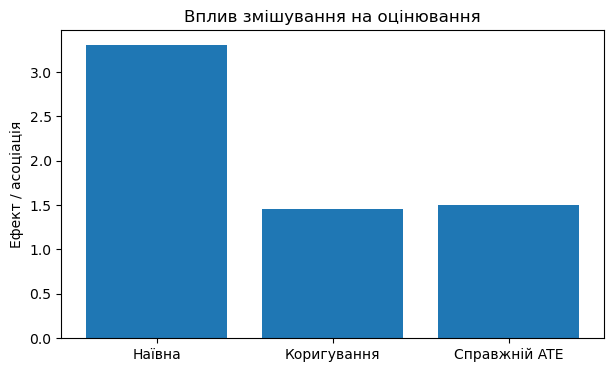

In [3]:
from sklearn.linear_model import LinearRegression

adjusted_model = LinearRegression()
adjusted_model.fit(data[["T", "C"]], data["Y"])

adjusted_ate = float(adjusted_model.coef_[0])
print("Наївна різниця:", round(naive, 3))
print("Скоригована оцінка:", round(adjusted_ate, 3))
print("Справжній ATE:", round(true_ate, 3))

fig, ax = plt.subplots(figsize=(7, 4))
names = ["Наївна", "Коригування", "Справжній ATE"]
values = [naive, adjusted_ate, true_ate]
ax.bar(names, values)
ax.set(ylabel="Ефект / асоціація",
       title="Вплив змішування на оцінювання")
plt.show()


## 8.3. Приклад backdoor-коригування

Нехай $C\in\{0,1\}$, $P(C=0)=P(C=1)=0.5$.

| $C$ | $\mathbb{E}(Y\mid T=0,C)$ | $\mathbb{E}(Y\mid T=1,C)$ | Різниця |
|---|---:|---:|---:|
| 0 | 2 | 4 | 2 |
| 1 | 7 | 9 | 2 |

За умов обмінності та позитивності:

$$
ATE=0.5(4-2)+0.5(9-7)=2.
$$

Це обчислення демонструє *стандартизацію за розподілом конфаундера*. Без інформації про частки страт і механізм призначення наївне порівняння груп не відтворює таке коригування.

# 9. Ідентифікація, оцінювання, перевірка

Три різні запитання:

1. *Ідентифікація (identification):* чи можна виразити шуканий причинний ефект через розподіл спостережуваних даних за сформульованих припущень?
2. *Оцінювання (estimation):* яким статистичним методом і з якою невизначеністю обчислити ідентифіковану величину?
3. *Валідація (validation):* які припущення можна перевірити емпірично, які -- лише предметно обґрунтувати, і як чутливий висновок до можливих порушень?

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Причинне<br/>питання") --> B("DAG та<br/>припущення")
 B --> C("Ідентифікація")
 C --> D("Оцінювання")
 D --> E("Аудит<br/>припущень")
 E --> F("Обмежене<br/>причинне твердження")
```

## Перевірка позитивності

Позитивність вимагає наявності шансів отримати обидва рівні втручання за релевантних значень $C$. На практиці важливо дослідити перекриття (overlap) розподілів конфаундерів між групами. Навіть якщо теоретично ймовірності не дорівнюють 0 або 1, слабке перекриття може зробити оцінювання нестійким.


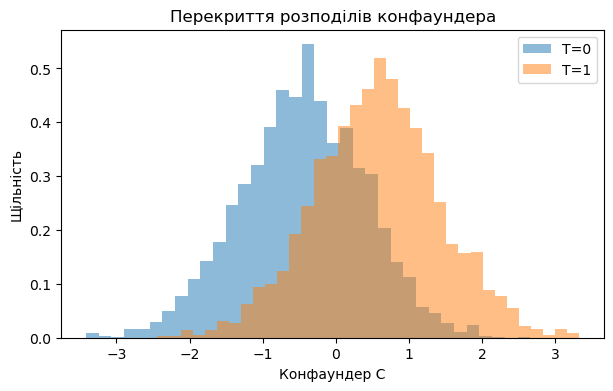

Частка propensity < 0.05: 0.03
Частка propensity > 0.95: 0.009


In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for t, label in [(0, "T=0"), (1, "T=1")]:
    ax.hist(C[T == t], bins=35, alpha=0.5, density=True, label=label)
ax.set(xlabel="Конфаундер C", ylabel="Щільність",
       title="Перекриття розподілів конфаундера")
ax.legend()
plt.show()

print("Частка propensity < 0.05:",
      round(float(np.mean(propensity < 0.05)), 3))
print("Частка propensity > 0.95:",
      round(float(np.mean(propensity > 0.95)), 3))


## Межі емпіричної перевірки

За спостережуваними даними можна аналізувати перекриття, баланс виміряних змінних, чутливість до специфікації моделі та альтернативних наборів коригування. Але відсутність *невиміряного* змішування не можна довести лише хорошою прогнозною якістю чи високою точністю регресії.

# 10. Типові загрози причинному висновку

| Загроза | Як виникає | Методологічний контроль |
|---|---|---|
| Невиміряне змішування | Спільна причина $T$ і $Y$ не спостерігається | Предметна аргументація, аналіз чутливості |
| Selection bias | Відбір залежить від колайдера | Аудит механізму включення |
| Порушення позитивності | Окремі страти мають майже один рівень $T$ | Overlap-діагностика |
| Коригування на медіатор | Частина загального ефекту блокується | DAG, визначення цільового ефекту |
| Порушення консистентності | Різні версії втручання змішуються | Чіткий опис інтервенції |
| Інтерференція | Втручання для одного впливає на інших | Дизайн на рівні груп/мереж |
| Часове змішування | Причини й наслідки неправильно впорядковані | Часовий протокол, target trial |

Для соціальних мереж інтерференція особливо важлива: дії одного користувача можуть змінювати результати інших. Тому індивідуальні потенційні наслідки $Y_i(t)$ можуть бути недостатніми без моделі мережевих взаємодій.

# 11. Зв'язок із дисертаційним дослідженням

Після *Explanation Audit v0.5* аспірант переходить до *Causal Research Specification v0.6*. Це ще не оцінювання складними Causal ML-методами, а формалізація причинного питання та перевірка його ідентифікованості.

Мінімальний склад артефакту:

1. *Втручання (treatment)*: що саме означає $T=1$ та $T=0$?
2. *Результат (outcome)*: що і коли вимірюється?
3. *Одиниця аналізу та популяція*: для кого визначається ефект?
4. *Estimand*: ATE, ATT або інша величина.
5. *DAG*: предметно обґрунтований причинний граф.
6. *Набір коригування*: які змінні вимірюємо й чому?
7. *Припущення*: консистентність, обмінність, позитивність, інтерференція.
8. *Межі висновку*: що не можна ідентифікувати за наявних даних?

Приклад причинного питання для дослідження ботоподібної активності: *«Чи змінює раннє обмеження автоматизованих облікових записів подальшу частку координованих повідомлень у дискусії?»* Тут потрібні чітко визначене втручання, часова вісь, одиниця аналізу та модель мережевих впливів. Сам факт кореляції між обмеженням і активністю не відповідає на це питання.

# 12. Перехід до Causal Machine Learning

У лекції 7 розглядатимемо, як машинне навчання допомагає оцінювати причинні ефекти за складних залежностей: показники схильності (propensity scores), двічі стійкі оцінювачі, мета-алгоритми, причинні ліси та Double/Debiased Machine Learning.

Важливо: гнучка ML-модель *не усуває* порушення причинних припущень. Спочатку -- причинна постановка та ідентифікація, потім -- статистичне оцінювання.

# Контрольні питання

1. Чому кореляція не доводить причинність?
2. Чим $P(Y\mid T)$ відрізняється від $P(Y\mid do(T))$?
3. Що таке потенційні наслідки та контрфактуали?
4. Чому неможливо безпосередньо спостерігати індивідуальний ефект?
5. Як визначаються ATE та ATT?
6. Що таке DAG і чому він є моделлю припущень?
7. Чим відрізняються конфаундер, медіатор і колайдер?
8. Як коригування на колайдер створює selection bias?
9. Що формулює backdoor criterion?
10. Як отримати формулу backdoor-коригування?
11. Що означають консистентність, обмінність і позитивність?
12. Чим відрізняються ідентифікація та оцінювання?
13. Чому висока точність ML-моделі не усуває змішування?
14. Які особливі труднощі виникають для причинного аналізу соціальних мереж?
15. Як сформулювати причинне питання в межах власної дисертації?

# Висновки

Причинний висновок вимагає переходу від спостережуваних залежностей до чітко визначених втручань і потенційних наслідків. DAG, backdoor criterion та припущення про обмінність, консистентність і позитивність задають умови, за яких причинне твердження можна обґрунтувати. Вони не замінюються якістю прогнозної моделі або її XAI-поясненнями.

# Література та ресурси

Основні джерела: [@pearl2009causality; @hernan2020causal; @peters2017elements].

Додатково: [The Book of Why (Pearl)](https://www.basicbooks.com/titles/judea-pearl/the-book-of-why/9780465097609/); [Causal Inference: What If](https://www.hsph.harvard.edu/miguel-hernan/causal-inference-book/).

::: {#refs}
:::
